# 02 · Portfolio construction: what does each slice of equity buy, and what does it cost?

**Owner:** _[name]_ · **Reviewed by:** _[name]_ · **Covers:** brief Layer 1 (Markowitz, CAPM, KPIs), spec §5 steps 2–3, gaps G3, G5, G19, G22, G24, hypotheses H5–H6
**Status:** analysis drafted with AI assistance; the owner must re-run it, check every finding against the output and rewrite it before sign-off (gap G12).

**The business question.** The committee has one real choice: how much of the endowment to hold in equities. More equity should mean more long-run return but deeper losses in a crisis. This notebook measures that trade-off honestly, so the decision notebook (06) can recommend a point on it.

**Provisional inputs (dry run, decided by the team later; each is one line to change):** caps from spec §4 with AGG ≤ 65% (decision D3) and GLD ≤ 15%; equity risk premium 4% (D4); decision date 2022-12-30 (the last day before the test lock). All data ≤ 2022-12-31. This notebook does not import the project package.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
wide = lambda col: raw.pivot(index="date", columns="ticker", values=col).sort_index()[TICKERS]
adj, close, div = wide("adj_close"), wide("close"), wide("dividends").fillna(0)
R = adj.pct_change(fill_method=None).iloc[1:]                      # simple returns: aggregate across assets

dtb3 = pd.read_parquet(RAW / "fred_DTB3.parquet").iloc[:, -1]
dtb3.index = pd.to_datetime(dtb3.index)
dd = dtb3.reindex(R.index, method="ffill") / 100
rf = ((1 + 365 * dd / (360 - 91 * dd)) ** (1 / 252) - 1).shift(1).bfill()   # T-bill, bond-equivalent, lagged 1 day

EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # D3 (agreed 2026-10-28)
ERP = 0.045                                                                                   # D4 (agreed 2026-10-28)
W = 756                                                                                       # 3-year estimation window (§5)
COST = 5e-4                                                                                   # 5 bp per side
ASSET_COLOURS = {"SPY": "#2a78d6", "EFA": "#eb6834", "EEM": "#1baf7a", "XLE": "#eda100", "XLK": "#e87ba4",
                 "GLD": "#008300", "AGG": "#6250d6"}                                          # fixed order, validated palette

def solve(objective, bounds, extra=()):
    res = optimize.minimize(objective, np.full(7, 1 / 7), bounds=bounds, method="SLSQP",
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}, *extra],
                            options={"ftol": 1e-12, "maxiter": 2000})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

def lw_cov(window):
    return LedoitWolf().fit(window.to_numpy()).covariance_ * 252

CAP_BOUNDS = [(0.0, CAPS[t]) for t in TICKERS]

def min_var_at(x, S, bounds=CAP_BOUNDS):
    """Minimum variance with the equity share fixed at x, under the caps."""
    return solve(lambda w: w @ S @ w, bounds, [{"type": "eq", "fun": lambda w: EQ @ w - x}])

print(f"decision date {R.index[-1].date()}, estimation window {R.index[-W].date()} to {R.index[-1].date()}")

decision date 2022-12-30, estimation window 2020-01-02 to 2022-12-30


## 1 · The textbook answer: Markowitz with CAPM expected returns

The brief requires us to start here. Expected returns come from CAPM (μᵢ = r_f + βᵢ × ERP, with β against SPY), risk from a Ledoit-Wolf covariance. Then the optimiser picks the maximum-Sharpe (tangency) portfolio.

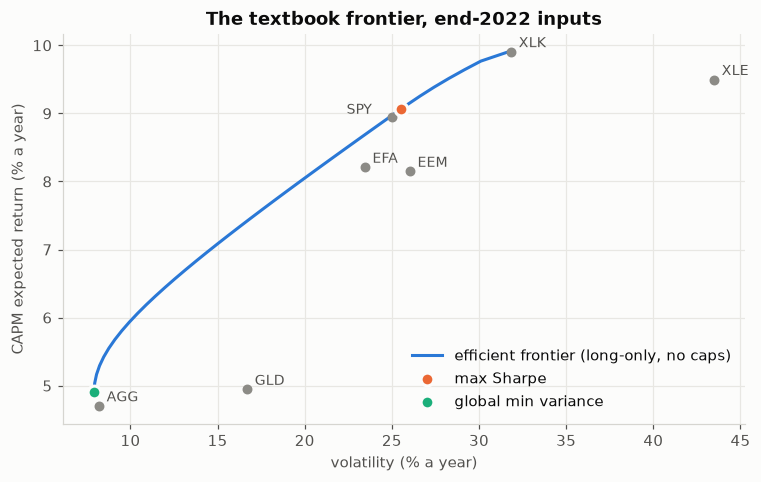

,SPY,EFA,EEM,AGG,GLD,XLE,XLK
max Sharpe,65.6%,10.4%,0.0%,0.4%,0.0%,3.5%,20.0%
global min variance,2.3%,0.0%,2.3%,85.6%,9.7%,0.2%,0.0%


In [3]:
est = R.iloc[-W:]
S = lw_cov(est)
cov = est.cov()
beta = cov["SPY"] / cov.loc["SPY", "SPY"]
rf_ann = float((1 + rf.iloc[-1]) ** 252 - 1)
mu = (rf_ann + beta * ERP).to_numpy()
free = [(0.0, 1.0)] * 7
w_tan = solve(lambda w: -(w @ mu - rf_ann) / np.sqrt(w @ S @ w), free)
w_gmv = solve(lambda w: w @ S @ w, free)

targets = np.linspace(w_gmv @ mu, mu.max() * 0.999, 40)
curve = [(np.sqrt(w @ S @ w), w @ mu) for w in
         (solve(lambda w: w @ S @ w, free, [{"type": "eq", "fun": lambda w, t=t: w @ mu - t}]) for t in targets)]
vol_a = np.sqrt(np.diag(S))

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot([c[0] * 100 for c in curve], [c[1] * 100 for c in curve], color=BLUE, label="efficient frontier (long-only, no caps)")
ax.scatter(vol_a * 100, mu * 100, color=GREY, s=30, zorder=3)
for t, v, m in zip(TICKERS, vol_a, mu):
    ax.annotate(t, (v * 100, m * 100), xytext=(-30, 2) if t == "SPY" else (5, 3), textcoords="offset points",
                fontsize=9, color=INK2)
for w, lab, colr in [(w_tan, "max Sharpe", ORANGE), (w_gmv, "global min variance", AQUA)]:
    ax.scatter(np.sqrt(w @ S @ w) * 100, w @ mu * 100, color=colr, s=70, zorder=4, edgecolor=SURFACE, linewidth=2, label=lab)
ax.set(xlabel="volatility (% a year)", ylabel="CAPM expected return (% a year)", title="The textbook frontier, end-2022 inputs")
ax.legend(loc="lower right")
plt.show()
pd.DataFrame({"max Sharpe": w_tan, "global min variance": w_gmv}, index=TICKERS).T.style.format("{:.1%}")

**Finding:** the textbook answer is two corners, neither of them usable. Maximum Sharpe holds about 66% SPY, 20% XLK, 10% EFA and almost no bonds (essentially 100% equity); global minimum variance holds about 86% AGG. That is by construction: CAPM expected returns rank assets only by their beta to SPY, so the "best" risky portfolio is close to the market itself and bonds and gold earn nothing extra.
**Decision:** show this frontier on the Portfolio page because the brief requires Layer 1, explain in one sentence why its corners are not the recommendation, and build the real frontier in §2 by controlling risk at each equity share (gap G3).

In [4]:
# CAPM regressions per ETF, 2004-11 to 2022: excess ETF return on excess SPY return, Newey-West errors
ex = R.sub(rf, axis=0)
rows = []
for t in TICKERS:
    y, x = ex[t], sm.add_constant(ex["SPY"])
    m = sm.OLS(y, x).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    b1 = sm.OLS(y.loc[:"2012-12-31"], x.loc[:"2012-12-31"]).fit().params["SPY"]
    b2 = sm.OLS(y.loc["2013-01-01":], x.loc["2013-01-01":]).fit().params["SPY"]
    rows.append({"ETF": t, "beta": m.params["SPY"], "alpha (% a year)": m.params["const"] * 252 * 100,
                 "alpha HAC t": m.tvalues["const"], "R²": m.rsquared,
                 "residual Ljung-Box p": acorr_ljungbox(m.resid, lags=[10])["lb_pvalue"].iloc[0],
                 "beta 2004-12": b1, "beta 2013-22": b2})
capm = pd.DataFrame(rows).set_index("ETF")
capm.round(3)

,beta,alpha (% a year),alpha HAC t,R²,residual Ljung-Box p,beta 2004-12,beta 2013-22
ETF,,,,,,,
SPY,1.000,0.000,2.051,1.000,0.000,1.000,1.000
EFA,1.004,-3.716,-1.727,0.800,0.000,1.115,0.861
EEM,1.235,-3.126,-0.869,0.693,0.010,1.482,0.917
AGG,-0.007,1.764,1.581,0.001,0.000,-0.026,0.018
GLD,0.047,7.354,1.764,0.003,0.663,0.065,0.025
XLE,1.181,0.512,0.107,0.556,0.000,1.234,1.114
XLK,1.045,2.928,1.577,0.845,0.000,0.936,1.186


**Finding:** no ETF has an alpha significantly different from zero (all |t| < 2; the largest are GLD +7.4% a year, t = 1.76, and EFA −3.7%, t = −1.73), which is what CAPM predicts. Betas are not stable: EEM fell from 1.48 (2004–12) to 0.92 (2013–22) and XLK rose from 0.94 to 1.19. The residuals of EFA, EEM, AGG, XLE and XLK are autocorrelated (Ljung-Box p ≈ 0), partly because foreign markets close before New York, so the Newey-West errors are required.
**Decision:** treat CAPM expected returns as a rough prior, never as a forecast to optimise on; disclose beta instability as a limitation.

## 2 · The frontier we will actually use: minimum variance at each equity share

Because expected returns are the least reliable input, we let the optimiser control **risk only**: for each equity share x, find the minimum-variance mix under the caps. Expected returns are used later only to **score** the points (notebook 06). Note what the caps imply: AGG ≤ 65% and GLD ≤ 15% leave at least 20% for equities, so 20% is the lowest feasible equity share.

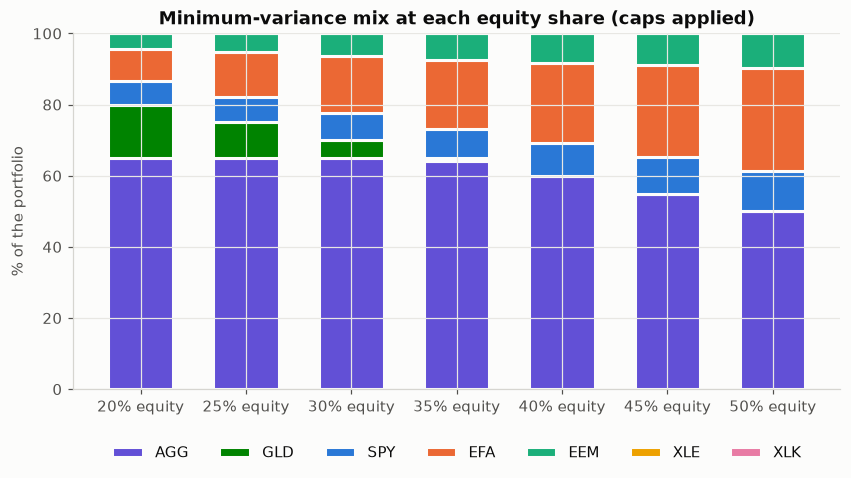

,SPY,EFA,EEM,AGG,GLD,XLE,XLK,volatility,binding caps,at zero
20% equity,6.7%,9.1%,4.2%,65.0%,15.0%,0.0%,0.0%,8.78%,"AGG, GLD","XLE, XLK"
25% equity,7.1%,12.5%,5.3%,65.0%,10.0%,0.0%,0.0%,9.20%,AGG,"XLE, XLK"
30% equity,7.6%,16.0%,6.4%,65.0%,5.0%,0.0%,0.0%,9.76%,AGG,"XLE, XLK"
35% equity,8.2%,19.4%,7.4%,64.1%,0.9%,0.0%,0.0%,10.45%,none,"XLE, XLK"
40% equity,9.2%,22.6%,8.2%,60.0%,0.0%,0.0%,0.0%,11.22%,none,"GLD, XLE, XLK"
45% equity,10.3%,25.8%,9.0%,55.0%,0.0%,0.0%,0.0%,12.05%,none,"GLD, XLE, XLK"
50% equity,11.4%,28.9%,9.7%,50.0%,0.0%,0.0%,0.0%,12.93%,none,"GLD, XLE, XLK"


In [5]:
LEVELS = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
front = pd.DataFrame({x: min_var_at(x, S) for x in LEVELS}, index=TICKERS).T
front.index = [f"{x:.0%} equity" for x in LEVELS]
front["volatility"] = [np.sqrt(w @ S @ w) for w in front[TICKERS].to_numpy()]
front["binding caps"] = [", ".join(t for i, t in enumerate(TICKERS) if w[i] >= CAPS[t] - 1e-6) or "none"
                         for w in front[TICKERS].to_numpy()]
front["at zero"] = [", ".join(t for i, t in enumerate(TICKERS) if w[i] < 1e-4) or "none" for w in front[TICKERS].to_numpy()]

fig, ax = plt.subplots(figsize=(9, 4.2))
bottom = np.zeros(len(front))
for t in ["AGG", "GLD", "SPY", "EFA", "EEM", "XLE", "XLK"]:
    ax.bar(front.index, front[t] * 100, bottom=bottom, color=ASSET_COLOURS[t], width=0.62,
           edgecolor=SURFACE, linewidth=2, label=t)
    bottom += front[t].to_numpy() * 100
ax.set(ylabel="% of the portfolio", title="Minimum-variance mix at each equity share (caps applied)")
ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()
front.style.format({**{t: "{:.1%}" for t in TICKERS}, "volatility": "{:.2%}"})

**Finding:** XLE and XLK get zero weight at every equity share; the equity sleeve is EFA, SPY and EEM. At 20% equity both the AGG and GLD caps bind (20% is the lowest feasible share), at 25–30% the AGG cap binds, and from 35% **no cap binds**. Measured on 2020–22 data, even the 20% point has 8.8% volatility: the last three years (COVID and the 2022 bond crash) were much riskier for bonds than the long run (the same point realised 6.2% over 2008–22).
**Decision:** prefer a recommended point where no cap binds (35% equity or more), so the recommendation is driven by risk, not by a number we typed (spec §4). Calibrate risk limits through the cycle, not on the latest window: on 2020–22 data the old 8% volatility limit would rule out every point (gap G4).

In [6]:
# Cap sensitivity at 30% equity: how much do the results move if a cap moves by 5 pp?
def point(bounds):
    w = min_var_at(0.30, S, bounds)
    return {**dict(zip(TICKERS, w)), "volatility": np.sqrt(w @ S @ w)}
cases = {"base (AGG 65, GLD 15)": CAP_BOUNDS}
for name, t, c in [("AGG cap 60", "AGG", .60), ("AGG cap 70", "AGG", .70), ("GLD cap 10", "GLD", .10), ("GLD cap 20", "GLD", .20)]:
    b = list(CAP_BOUNDS); b[TICKERS.index(t)] = (0.0, c); cases[name] = b
pd.DataFrame({k: point(v) for k, v in cases.items()}).T.style.format("{:.1%}")

,SPY,EFA,EEM,AGG,GLD,XLE,XLK,volatility
"base (AGG 65, GLD 15)",7.6%,16.0%,6.4%,65.0%,5.0%,0.0%,0.0%,9.8%
AGG cap 60,8.2%,15.7%,6.1%,60.0%,10.0%,0.0%,0.0%,9.8%
AGG cap 70,7.3%,16.1%,6.6%,67.7%,2.3%,0.0%,0.0%,9.8%
GLD cap 10,7.6%,16.0%,6.4%,65.0%,5.0%,0.0%,0.0%,9.8%
GLD cap 20,7.6%,16.0%,6.4%,65.0%,5.0%,0.0%,0.0%,9.8%


**Finding:** moving the AGG cap from 60% to 70%, or the GLD cap from 10% to 20%, changes the mix (AGG and gold trade places) but not the risk: volatility stays at 9.8% in every case. At 30% equity the GLD cap does not bind at all.
**Decision:** decision D3 (the AGG cap) can be made on concentration grounds alone; it does not move the risk of a 30% portfolio.

## 3 · Is the allocation stable enough to defend?

A committee will not accept weights that jump around when the data changes slightly. We resample the estimation window (blocks of 20 days, 50 times) and re-optimise, comparing minimum variance with Min-CVaR (99%) at the same 30% equity share.

99% CVaR on 756 days rests on 7.6 tail observations


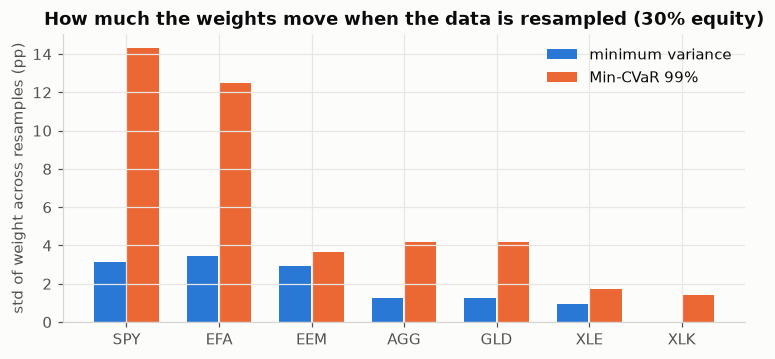

,SPY,EFA,EEM,AGG,GLD,XLE,XLK
minimum variance,3.16,3.46,2.90,1.25,1.25,0.93,0.0
Min-CVaR 99%,14.33,12.50,3.68,4.17,4.17,1.71,1.4


In [7]:
X = est.to_numpy(); n = len(X); a = 0.99
def min_cvar_at(x, Xs):
    c = np.r_[np.zeros(7), 1.0, np.full(n, 1 / ((1 - a) * n))]
    A_ub = np.c_[-Xs, -np.ones(n), -np.eye(n)]
    A_eq = np.vstack([np.r_[np.ones(7), 0, np.zeros(n)], np.r_[EQ, 0, np.zeros(n)]])
    res = optimize.linprog(c, A_ub=A_ub, b_ub=np.zeros(n), A_eq=A_eq, b_eq=[1, x],
                           bounds=CAP_BOUNDS + [(None, None)] + [(0, None)] * n, method="highs")
    assert res.success, res.message
    return res.x[:7]
rng = np.random.default_rng(20261028)
mv_w, cv_w = [], []
for _ in range(50):
    idx = (rng.integers(0, n - 20, n // 20 + 1)[:, None] + np.arange(20)).ravel()[:n]
    Xb = X[idx]
    mv_w.append(min_var_at(0.30, LedoitWolf().fit(Xb).covariance_ * 252))
    cv_w.append(min_cvar_at(0.30, Xb))
spread = pd.DataFrame({"minimum variance": np.std(mv_w, axis=0), "Min-CVaR 99%": np.std(cv_w, axis=0)}, index=TICKERS) * 100
print(f"99% CVaR on {n} days rests on {(1 - a) * n:.1f} tail observations")
fig, ax = plt.subplots(figsize=(8, 3.4))
xpos = np.arange(7)
ax.bar(xpos - 0.18, spread["minimum variance"], width=0.34, color=BLUE, label="minimum variance")
ax.bar(xpos + 0.18, spread["Min-CVaR 99%"], width=0.34, color=ORANGE, label="Min-CVaR 99%")
ax.set_xticks(xpos, TICKERS)
ax.set(ylabel="std of weight across resamples (pp)", title="How much the weights move when the data is resampled (30% equity)")
ax.legend(loc="upper right")
plt.show()
spread.round(2).T

**Finding:** Min-CVaR weights move 3–4 times more than minimum-variance weights when the data is resampled (SPY 14.3 vs 3.2 percentage points, EFA 12.5 vs 3.5), because its 99% tail rests on fewer than 8 observations.
**Decision:** build the frontier with minimum variance; keep Min-CVaR only as a robustness check (gap G5). A committee can defend weights that do not jump around.

## 4 · How would each point have done? Walk-forward 2008–2022

At every quarter-end the portfolio is rebuilt from the previous 3 years only (no look-ahead), held with drifting weights, and charged 5 bp per side. Each point is compared with a **plain benchmark with the same equity share** (x in SPY, the rest in AGG): this asks whether our seven-ETF diversification adds anything over a simple two-fund mix.

These are **historical** results, not forecasts: 2008–2022 was a period of falling bond yields that flatters bonds. Forward-looking returns come in notebook 06.

In [8]:
qe = R.index.to_series().groupby(R.index.to_period("Q")).max()
TAUS = [d for d in qe if d >= pd.Timestamp("2007-12-31") and d < R.index[-1] and R.index.get_loc(d) >= W - 1]

def simulate(weights):
    taus = sorted(weights)
    r = R.loc[R.index > taus[0]]
    v = weights[taus[0]].copy()
    out, turn = [], []
    prev = 1.0
    for date, row in zip(r.index, r.to_numpy()):
        v = v * (1 + row)
        if date in weights and date != taus[0]:
            tot = v.sum(); target = weights[date] * tot
            traded = np.abs(target - v).sum()
            v = target - COST * traded * weights[date]
            turn.append(traded / tot / 2)
        out.append(v.sum() / prev - 1); prev = v.sum()
    return pd.Series(out, index=r.index), float(np.sum(turn) / (len(r) / 252))

def walk(rule, window=W):
    return simulate({tau: rule(R.loc[:tau].iloc[-window:]) for tau in TAUS})

def max_dd(r):
    v = (1 + r).cumprod()
    return float((v / np.maximum(v.cummax(), 1.0) - 1).min())

def hist_es(r, a=0.99):
    loss = -r; q = loss.quantile(a)
    return float(loss[loss >= q].mean())

results, bench, turnover = {}, {}, {}
results["GMV (equity free)"], turnover["GMV (equity free)"] = walk(
    lambda e: solve(lambda w: w @ lw_cov(e) @ w, CAP_BOUNDS, [{"type": "ineq", "fun": lambda w: 0.5 - EQ @ w}]))
for x in [0.20, 0.30, 0.40, 0.50]:
    name = f"{x:.0%} equity"
    results[name], turnover[name] = walk(lambda e, x=x: min_var_at(x, lw_cov(e)))
    fixed = np.array([x if t == "SPY" else (1 - x if t == "AGG" else 0.0) for t in TICKERS])
    bench[name], _ = simulate({tau: fixed for tau in TAUS})
print(f"{len(TAUS)} quarterly rebalances, {results['20% equity'].index[0].date()} to {results['20% equity'].index[-1].date()}")

60 quarterly rebalances, 2008-01-02 to 2022-12-30


In [9]:
def hac_alpha(r, b):
    y = (r - rf.reindex(r.index)); x = sm.add_constant(b - rf.reindex(b.index))
    m = sm.OLS(y, x).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    return m.params["const"] * 252, m.tvalues["const"], m.pvalues["const"]

def sharpe(r):
    e = r - rf.reindex(r.index)
    return float(e.mean() / e.std() * np.sqrt(252))

def paired_sharpe_se(r1, r2, reps=1000, block=20):
    a, b, f = (r1 - rf.reindex(r1.index)).to_numpy(), (r2 - rf.reindex(r2.index)).to_numpy(), np.sqrt(252)
    m = len(a); out = []
    for _ in range(reps):
        idx = (rng.integers(0, m - block, m // block + 1)[:, None] + np.arange(block)).ravel()[:m]
        out.append(a[idx].mean() / a[idx].std() * f - b[idx].mean() / b[idx].std() * f)
    return float(np.std(out))

rows = []
ref = results["GMV (equity free)"]
for name, r in results.items():
    years = len(r) / 252
    cagr = float((1 + r).prod() ** (1 / years) - 1)
    e = r - rf.reindex(r.index)
    down = np.sqrt((np.minimum(e, 0) ** 2).mean()) * np.sqrt(252)
    b_spy = sm.OLS(e, sm.add_constant(R["SPY"].reindex(r.index) - rf.reindex(r.index))).fit().params.iloc[1]
    row = {"point": name, "CAGR": cagr, "volatility": r.std() * np.sqrt(252), "Sharpe": sharpe(r),
           "Sortino": e.mean() * 252 / down, "max drawdown": max_dd(r), "Calmar": cagr / abs(max_dd(r)),
           "99% ES (1 day)": hist_es(r), "beta to SPY": b_spy, "Treynor": e.mean() * 252 / b_spy,
           "turnover / yr": turnover[name]}
    if name in bench:
        a_, t_, p_ = hac_alpha(r, bench[name])
        act = r - bench[name]
        row.update({"alpha vs benchmark": a_, "alpha HAC p": p_, "info ratio": act.mean() / act.std() * np.sqrt(252),
                    "benchmark CAGR": float((1 + bench[name]).prod() ** (1 / years) - 1),
                    "benchmark max DD": max_dd(bench[name])})
    if name != "GMV (equity free)":
        row.update({"Sharpe − GMV": sharpe(r) - sharpe(ref), "paired SE": paired_sharpe_se(r, ref)})
    rows.append(row)
kpi = pd.DataFrame(rows).set_index("point")
pct = ["CAGR", "volatility", "max drawdown", "99% ES (1 day)", "turnover / yr", "alpha vs benchmark", "benchmark CAGR", "benchmark max DD"]
kpi.style.format({**{c: "{:.2%}" for c in pct}, **{c: "{:.3f}" for c in kpi.columns if c not in pct}}, na_rep="")

,CAGR,volatility,Sharpe,Sortino,max drawdown,Calmar,99% ES (1 day),beta to SPY,Treynor,turnover / yr,alpha vs benchmark,alpha HAC p,info ratio,benchmark CAGR,benchmark max DD,Sharpe − GMV,paired SE
point,,,,,,,,,,,,,,,,,
GMV (equity free),4.37%,6.29%,0.608,0.848,-18.16%,0.240,1.64%,0.203,0.189,8.51%,,,,,,,
20% equity,4.41%,6.20%,0.624,0.869,-17.97%,0.246,1.58%,0.182,0.213,7.63%,0.52%,0.452,0.135,4.05%,-17.83%,0.016,0.036
30% equity,4.68%,6.90%,0.603,0.844,-19.81%,0.236,1.88%,0.270,0.154,9.81%,0.08%,0.825,-0.054,4.76%,-20.14%,-0.005,0.070
40% equity,5.10%,8.37%,0.559,0.784,-22.46%,0.227,2.30%,0.363,0.129,12.91%,-0.11%,0.782,-0.191,5.43%,-22.87%,-0.048,0.117
50% equity,5.47%,10.06%,0.515,0.722,-27.88%,0.196,2.76%,0.456,0.114,13.01%,-0.32%,0.528,-0.282,6.07%,-28.30%,-0.093,0.134


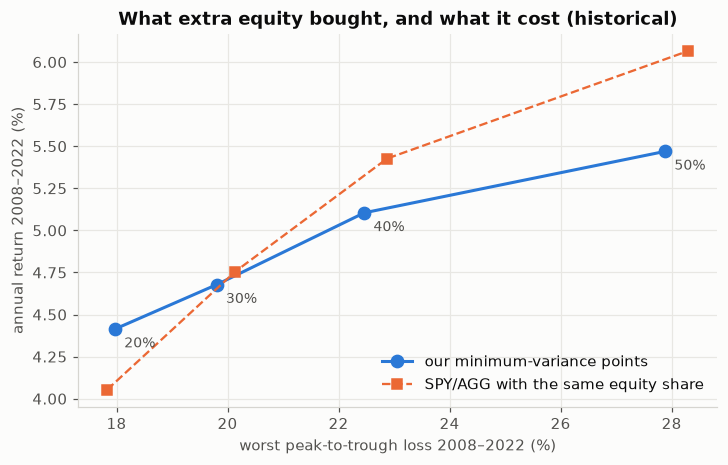

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.4))
pts = kpi.loc[[k for k in kpi.index if k.endswith("equity")]]
ax.plot(-pts["max drawdown"] * 100, pts["CAGR"] * 100, color=BLUE, marker="o", markersize=8, label="our minimum-variance points")
bm = pts.dropna(subset=["benchmark CAGR"])
ax.plot(-bm["benchmark max DD"] * 100, bm["benchmark CAGR"] * 100, color=ORANGE, marker="s", markersize=7,
        linestyle="--", linewidth=1.5, label="SPY/AGG with the same equity share")
for name, rw in pts.iterrows():
    ax.annotate(name.replace(" equity", "%").replace("%%", "%"), (-rw["max drawdown"] * 100, rw["CAGR"] * 100),
                xytext=(6, -12), textcoords="offset points", fontsize=9, color=INK2)
ax.set(xlabel="worst peak-to-trough loss 2008–2022 (%)", ylabel="annual return 2008–2022 (%)",
       title="What extra equity bought, and what it cost (historical)")
ax.legend(loc="lower right")
plt.show()

**Finding:**
- **Each extra 10 percentage points of equity bought about +0.35 pp a year of return and cost about 3.3 pp of extra crisis loss.** From 20% to 50% equity, return rose from 4.4% to 5.5% a year, the worst loss deepened from −18% to −28%, and the 1-day 99% ES rose from 1.6% to 2.8%. On USD 10M: about +USD 35,000 a year of return for about USD 330,000 more at the bottom of a crisis, per 10 points of equity.
- **Risk-adjusted, every point is the same.** Sharpe ratios fall slightly (0.62 to 0.52), but every difference from GMV is within about one paired standard error (hypothesis H6 supported). So the choice is how much risk the endowment can bear, not which portfolio is "more efficient".
- **Our seven-ETF diversification did not beat a plain SPY/AGG mix** with the same equity share: ahead at 20% equity (+0.4 pp), behind at 30–50% (−0.1 to −0.6 pp), and the alpha is never significant (p = 0.45–0.83; H5 supported). The minimum-variance equity sleeve leans on EFA and EEM, and international equities lagged the US badly over 2008–22.
- No point reaches the pipeline's backward-looking 6.7% required return; the forward-looking test is notebook 06.

**Decision:** present the trade-off to the committee in dollars per 10 points of equity. Be honest that international diversification cost return in hindsight; it is insurance against a single-country shock, not a source of extra return. Consider, as a team decision, an equity sleeve closer to market weights (more SPY) and compare the two in notebook 06.

## 5 · Why a 3-year lookback?

The window is a trade-off: longer windows give steadier estimates; shorter ones react faster to a new regime. We rerun the 30%-equity point with 2, 3 and 4-year windows.

In [11]:
rows = []
for win in [500, 756, 1000]:
    r, tv = walk(lambda e: min_var_at(0.30, lw_cov(e)), window=win)
    rows.append({"window (days)": win, "CAGR": float((1 + r).prod() ** (252 / len(r)) - 1), "volatility": r.std() * np.sqrt(252),
                 "max drawdown": max_dd(r), "99% ES (1 day)": hist_es(r), "turnover / yr": tv})
pd.DataFrame(rows).set_index("window (days)").style.format("{:.2%}")

,CAGR,volatility,max drawdown,99% ES (1 day),turnover / yr
window (days),,,,,
500,4.62%,6.91%,-19.64%,1.87%,12.78%
756,4.68%,6.90%,-19.81%,1.88%,9.81%
1000,4.73%,6.91%,-19.81%,1.88%,8.27%


**Finding:** the window barely matters for outcomes: return 4.6–4.7% a year and worst loss −19.6% to −19.8% for 2, 3 and 4 years. It matters for trading: turnover falls from 12.8% to 9.8% to 8.3% a year as the window lengthens.
**Decision:** keep 3 years (756 days): the same results as 4 years with a faster reaction to a new regime, and a quarter less trading than 2 years. Say plainly that the result does not depend on this choice (gap G24).

## 6 · How much of the spending can income pay?

The brief lists income generation as an objective. Trailing 12-month distributions to the decision date, divided by price, give each ETF's yield. A Sri Lankan endowment pays US withholding on dividends (15% under the treaty) on the equity ETFs; AGG's interest-related dividends may be exempt (§871(k), to confirm with a tax adviser), so we show AGG both ways. GLD pays nothing.

In [12]:
last = R.index[-1]
yield_ = div.loc[last - pd.Timedelta(days=365):last].sum() / close.loc[last]
wht = pd.Series({t: 0.15 if t in EQUITY else 0.0 for t in TICKERS})
net_exempt = yield_ * (1 - wht)
net_taxed = yield_ * (1 - wht.where(wht > 0, 0.15).where(pd.Index(TICKERS) != "GLD", 0.0))
inc = pd.DataFrame({"gross yield": yield_, "net, AGG exempt": net_exempt, "net, AGG taxed": net_taxed}).T
display(inc.style.format("{:.2%}"))
rows = []
for name, w in front[TICKERS].iterrows():
    lo_, hi_ = float(w @ net_taxed), float(w @ net_exempt)
    rows.append({"point": name, "net income yield (AGG taxed)": lo_, "net income yield (AGG exempt)": hi_,
                 "share of 4% spending covered": f"{lo_ / 0.04:.0%}–{hi_ / 0.04:.0%}"})
pd.DataFrame(rows).set_index("point").style.format({c: "{:.2%}" for c in ["net income yield (AGG taxed)", "net income yield (AGG exempt)"]})

ticker,SPY,EFA,EEM,AGG,GLD,XLE,XLK
gross yield,1.65%,2.94%,2.56%,2.39%,0.00%,3.68%,1.04%
"net, AGG exempt",1.40%,2.50%,2.18%,2.39%,0.00%,3.13%,0.88%
"net, AGG taxed",1.40%,2.50%,2.18%,2.03%,0.00%,3.13%,0.88%


,net income yield (AGG taxed),net income yield (AGG exempt),share of 4% spending covered
point,,,
20% equity,1.73%,1.97%,43%–49%
25% equity,1.85%,2.08%,46%–52%
30% equity,1.97%,2.20%,49%–55%
35% equity,2.06%,2.29%,52%–57%
40% equity,2.09%,2.31%,52%–58%
45% equity,2.10%,2.30%,53%–57%
50% equity,2.11%,2.29%,53%–57%


**Finding:** after withholding tax, the portfolios yield about 1.7–2.3% a year, so distributions cover roughly **45–58%** of a 4% spending rate; the rest must come from selling assets. Whether AGG's distributions are exempt from withholding is worth about 0.2 pp of income on a 65% AGG holding. These are trailing 2022 distributions: AGG's trailing yield (2.4%) lags the higher bond yields of late 2022, so forward income will be higher.
**Decision:** state in the memo that income pays about half of spending and the rest is funded by selling assets, which is why drawdowns matter (gap G22). Ask a tax adviser about the AGG exemption; use forward yields in notebook 06.

## 7 · Reconciliation with the pipeline

Our walk-forward engine is independent code. The pipeline now uses the agreed caps (D3) and carries the pre-registered **35%-equity frontier point** as its focus portfolio. Both series must match ours: the 35% point, and the global minimum variance under the same caps.

In [13]:
pipe = pd.read_parquet(ART / "wf_performance_val.parquet")
gmv_ours, _ = walk(lambda e: solve(lambda w: w @ lw_cov(e) @ w, CAP_BOUNDS, [{"type": "ineq", "fun": lambda w: 0.5 - EQ @ w}]))
x35_ours, _ = walk(lambda e: min_var_at(0.35, lw_cov(e)))
rows = []
for name, ours, col in [("35% equity frontier", x35_ours, "Frontier 35% equity"), ("Global minimum variance", gmv_ours, "Global min variance")]:
    theirs = pipe[col].dropna()
    common = ours.index.intersection(theirs.index)
    a, b = ours[common], theirs[common]
    rows.append({"series": name, "days": len(common), "correlation": a.corr(b), "largest daily difference": (a - b).abs().max(),
                 "CAGR ours": (1 + a).prod() ** (252 / len(a)) - 1, "CAGR pipeline": (1 + b).prod() ** (252 / len(b)) - 1})
recon = pd.DataFrame(rows).set_index("series")
assert (recon["correlation"] > 0.9999).all(), "our walk-forward and the pipeline's disagree"
recon.style.format({"correlation": "{:.6f}", "largest daily difference": "{:.1e}", "CAGR ours": "{:.4%}", "CAGR pipeline": "{:.4%}"})

,days,correlation,largest daily difference,CAGR ours,CAGR pipeline
series,,,,,
35% equity frontier,3777,1.000000,3.4e-06,4.9086%,4.9086%
Global minimum variance,3777,1.000000,2.5e-06,4.3657%,4.3657%


**Finding:** our independent walk-forward reproduces both pipeline series: the 35% frontier point the pipeline now carries (and backtests for the final test) and the global minimum variance under the same caps. The table above gives the correlation, the largest daily difference and both CAGRs.

## Evidence table and what it means for the endowment

| Claim | Evidence | Status |
|---|---|---|
| The textbook Markowitz/CAPM optimum is a corner | §1: max Sharpe ≈ 100% equity, GMV ≈ 86% AGG | **Strong** (by construction) |
| H5: our points earn no alpha over a same-equity SPY/AGG mix | §4: alpha HAC p = 0.45–0.83 | **Supported** |
| H6: no point has a significantly different Sharpe ratio | §4: all differences within ≈ 1 paired SE | **Supported** |
| Minimum variance is more stable than Min-CVaR | §3: 3–4× smaller weight dispersion | **Strong** |
| Caps stop binding at 35% equity | §2 | **Strong** (for this window; recheck at the decision date) |
| The lookback choice does not drive results | §5 | **Strong** |

**What this means for the endowment (input to the memo):**
1. The committee's real decision is **how much equity**, because every point is equally efficient. The price list: each extra 10 points of equity bought about **+0.35 pp a year** (≈ USD 35,000 on USD 10M) and cost about **3.3 pp more** at the bottom of a crisis (≈ USD 330,000).
2. Points from **35% equity** are where the recommendation comes from risk, not from caps.
3. Spreading equity beyond the US **cost return** in 2008–22; it is kept as insurance and disclosed as such.
4. Income pays about **half** of the spending; the rest comes from selling assets, so crisis losses translate directly into forced selling.
5. Historical returns fall short of the required return at every point; whether forward-looking returns close the gap is notebook 06's question.